# 🗳️ Cruzamento Eleitoral: Perfis Socioeconômicos x Eleições Presidenciais
## Votação no 1º Turno de 2026 (Lula x Flávio Bolsonaro), Série Histórica de Abstenção (2010–2026), Abstenção por Idade e Mapa do Brasil

### 🎯 Objetivos deste Caderno:
1. **Resultado do 1º Turno de 2026:** Analisar a média de votos de **Lula** e **Flávio Bolsonaro** (e demais candidatos) em cada um dos perfis socioeconômicos dos 5.571 municípios.
2. **Peso Eleitoral de Cada Perfil:** Calcular a fatia dos votos válidos do país que cada grupo representa e de onde vêm os votos de cada candidato.
3. **Série Histórica da Abstenção (2010 a 2026):** Acompanhar a evolução do comparecimento eleitoral em 5 eleições presidenciais consecutivas.
4. **Abstenção por Faixa Etária:** Identificar os padrões de abstenção entre jovens (16-24), adultos (25-59) e idosos (60+).
5. **Mapeamento Geoespacial do Brasil:** Plotar o mapa geográfico com todos os municípios brasileiros geolocalizados e coloridos de acordo com seu perfil socioeconômico.
6. **Exportação Consolidada:** Salvar as bases com indicadores socioeconômicos e eleitorais integrados.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

# Estilo editorial de visualização
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("✅ Ambiente configurado com pandas, matplotlib, seaborn e módulos geoespaciais!")


✅ Ambiente configurado com pandas, matplotlib, seaborn e módulos geoespaciais!


## 📂 1. Carregamento e Cruzamento das Bases de Dados
Integramos em uma única base nacional:
* Classificação dos **Perfis Socioeconômicos Reclassificados** (`classificacao_perfis_municipios_completa.xlsx`);
* Votação Presidencial do **1º Turno de 2026** (`votacao_presidencial_municipios_2026.csv`);
* Votação Presidencial de **2022** (`votacao_presidencial_municipios_2022.csv`);
* Série Histórica de **Abstenção 2010–2026** (`serie_historica_presidencial_2010_2022.csv` + 2026);
* Abstenção por **Faixa Etária** (`abstencao_idade_municipios_2022.csv`);
* Coordenadas Geográficas dos Municípios (`municipios_coordenadas.csv`).


In [2]:
# 1. Carregando Perfis Socioeconômicos Reclassificados
df_perfis = pd.read_excel('dados_prioridades/classificacao_perfis_municipios_completa.xlsx', sheet_name='Todos_Municipios_5571')
col_perfil = 'perfil_final_reclassificado' if 'perfil_final_reclassificado' in df_perfis.columns else 'nome_perfil_socioeconomico'

# 2. Carregando Votação 2026 (1º Turno)
df_2026 = pd.read_csv('dados_prioridades/eleicoes_tse/votacao_presidencial_municipios_2026.csv', sep=';')

# 3. Carregando Votação 2022 (para referência histórica)
df_2022 = pd.read_csv('dados_prioridades/eleicoes_tse/votacao_presidencial_municipios_2022.csv', sep=';')

# 4. Carregando Série Histórica TSE
df_hist = pd.read_csv('dados_prioridades/eleicoes_tse/serie_historica_presidencial_2010_2022.csv', sep=';')
df_hist['taxa_abst_2010'] = (df_hist['abstencao_2010_2t'] / df_hist['aptos_2010'].replace(0, np.nan) * 100).round(1)
df_hist['taxa_abst_2014'] = (df_hist['abstencao_2014_2t'] / df_hist['aptos_2014'].replace(0, np.nan) * 100).round(1)
df_hist['taxa_abst_2018'] = (df_hist['abstencao_2018_2t'] / df_hist['aptos_2018'].replace(0, np.nan) * 100).round(1)
df_hist['taxa_abst_2022'] = (df_hist['abstencao_2022_2t'] / df_hist['aptos_2022'].replace(0, np.nan) * 100).round(1)

# 5. Carregando Abstenção por Idade
df_idade = pd.read_csv('dados_prioridades/eleicoes_tse/abstencao_idade_municipios_2022.csv', sep=';')

# 6. Carregando Coordenadas Geográficas
df_geo = pd.read_csv('dados_prioridades/municipios_coordenadas.csv')
df_geo = df_geo.rename(columns={'codigo_ibge': 'cod_ibge7'})

# Cruzamento Geral (Merge)
df_eleitoral = df_perfis.copy()
df_eleitoral['perfil_analise'] = df_eleitoral[col_perfil]

# Merge com Eleições 2026
df_eleitoral = df_eleitoral.merge(
    df_2026[['cod_ibge7', 'votos_lula_2026_1t', 'votos_flavio_2026_1t', 'votos_caiado_2026_1t', 'votos_zema_2026_1t',
             'votos_validos_2026_1t', 'pct_lula_2026_1t', 'pct_flavio_2026_1t', 'pct_caiado_2026_1t', 'pct_zema_2026_1t',
             'vencedor_2026_1t', 'eleitores_aptos_2026', 'comparecimento_2026_1t', 'abstencao_2026_1t', 'taxa_abst_2026_1t']],
    on='cod_ibge7', how='left'
)

# Merge com Eleições 2022
df_eleitoral = df_eleitoral.merge(
    df_2022[['cod_ibge7', 'pct_lula_1t', 'pct_bolsonaro_1t', 'pct_lula_2t', 'pct_bolsonaro_2t']],
    on='cod_ibge7', how='left'
)

# Merge com Série Histórica
df_eleitoral = df_eleitoral.merge(
    df_hist[['cod_ibge7', 'taxa_abst_2010', 'taxa_abst_2014', 'taxa_abst_2018', 'taxa_abst_2022']],
    on='cod_ibge7', how='left'
)

# Merge com Abstenção por Idade
df_eleitoral = df_eleitoral.merge(
    df_idade[['cod_ibge7', 'taxa_abstencao_jovem_16_24_pct', 'taxa_abstencao_adulto_25_59_pct', 'taxa_abstencao_idoso_60_mais_pct']],
    on='cod_ibge7', how='left'
)

# Merge com Coordenadas
df_eleitoral = df_eleitoral.merge(
    df_geo[['cod_ibge7', 'latitude', 'longitude']],
    on='cod_ibge7', how='left'
)

print(f"✅ Base cruzada com sucesso: {len(df_eleitoral)} municípios com dados socioeconômicos e eleitorais de 2026 integrados!")


✅ Base cruzada com sucesso: 5571 municípios com dados socioeconômicos e eleitorais de 2026 integrados!


## ⚖️ 2. Peso Eleitoral: Quanto Cada Perfil Representa nos Votos do Brasil (2026)
Calculamos a participação real de cada perfil socioeconômico no eleitorado e nos votos válidos do **1º Turno de 2026**:
1. **% do Eleitorado Nacional 2026:** Proporção dos eleitores aptos no país.
2. **% dos Votos Válidos Nacionais 2026:** Fatia dos votos válidos apurados no 1º turno.
3. **Composição da Base de Votos:** De onde vieram os votos de **Lula** e de **Flávio Bolsonaro** (% do total nacional de cada candidato que veio de cada perfil).


In [3]:
total_aptos_26 = df_eleitoral['eleitores_aptos_2026'].sum()
total_validos_26 = df_eleitoral['votos_validos_2026_1t'].sum()
total_lula_26 = df_eleitoral['votos_lula_2026_1t'].sum()
total_flavio_26 = df_eleitoral['votos_flavio_2026_1t'].sum()

resumo_peso_26 = df_eleitoral.groupby('perfil_analise').agg({
    'cod_ibge7': 'count',
    'eleitores_aptos_2026': 'sum',
    'votos_validos_2026_1t': 'sum',
    'votos_lula_2026_1t': 'sum',
    'votos_flavio_2026_1t': 'sum'
})

resumo_peso_26['pct_eleitorado_nacional_2026'] = (resumo_peso_26['eleitores_aptos_2026'] / total_aptos_26 * 100).round(2)
resumo_peso_26['pct_votos_validos_nacional_2026'] = (resumo_peso_26['votos_validos_2026_1t'] / total_validos_26 * 100).round(2)
resumo_peso_26['pct_do_total_lula_2026'] = (resumo_peso_26['votos_lula_2026_1t'] / total_lula_26 * 100).round(2)
resumo_peso_26['pct_do_total_flavio_2026'] = (resumo_peso_26['votos_flavio_2026_1t'] / total_flavio_26 * 100).round(2)

resumo_peso_26 = resumo_peso_26.sort_values(by='pct_votos_validos_nacional_2026', ascending=False)

print("📊 PESO ELEITORAL DE CADA PERFIL NO 1º TURNO DE 2026:")
tabela_exib = resumo_peso_26[['cod_ibge7', 'eleitores_aptos_2026', 'pct_eleitorado_nacional_2026', 'votos_validos_2026_1t', 'pct_votos_validos_nacional_2026', 'pct_do_total_lula_2026', 'pct_do_total_flavio_2026']].copy()
tabela_exib.columns = ['Qtd_Cidades', 'Eleitores_Aptos_2026', '%_Eleitorado_BR', 'Votos_Validos_1T_2026', '%_Votos_Validos_BR', '%_Total_Votos_Lula', '%_Total_Votos_Flavio']
tabela_exib['Eleitores_Aptos_2026'] = tabela_exib['Eleitores_Aptos_2026'].map('{:,.0f}'.format)
tabela_exib['Votos_Validos_1T_2026'] = tabela_exib['Votos_Validos_1T_2026'].map('{:,.0f}'.format)
display(tabela_exib)


📊 PESO ELEITORAL DE CADA PERFIL NO 1º TURNO DE 2026:


,Qtd_Cidades,Eleitores_Aptos_2026,%_Eleitorado_BR,Votos_Validos_1T_2026,%_Votos_Validos_BR,%_Total_Votos_Lula,%_Total_Votos_Flavio
perfil_analise,,,,,,,
Polos Regionais de Emprego e Serviços,1134,"51,082,302",32.37,"37,851,888",31.82,25.34,37.08
Jovens e Dependentes de Apoio Social,1414,"38,946,357",24.68,"30,277,597",25.46,31.63,20.52
Cidades Autônomas e Agroindustriais,957,"39,569,030",25.08,"29,335,811",24.66,20.66,27.65
Municípios Dependentes de Seguridade e Repasses,766,"15,830,898",10.03,"12,151,592",10.22,15.84,5.58
Cidades da Terceira Idade e Aposentados,722,"6,993,001",4.43,"5,288,105",4.45,3.40,5.47
Pequenos Municípios do Funcionalismo Público,573,"2,882,216",1.83,"2,126,652",1.79,1.70,1.90
Grandes Metrópoles e Capitais (Atípicas),5,"2,486,461",1.58,"1,908,568",1.60,1.43,1.79


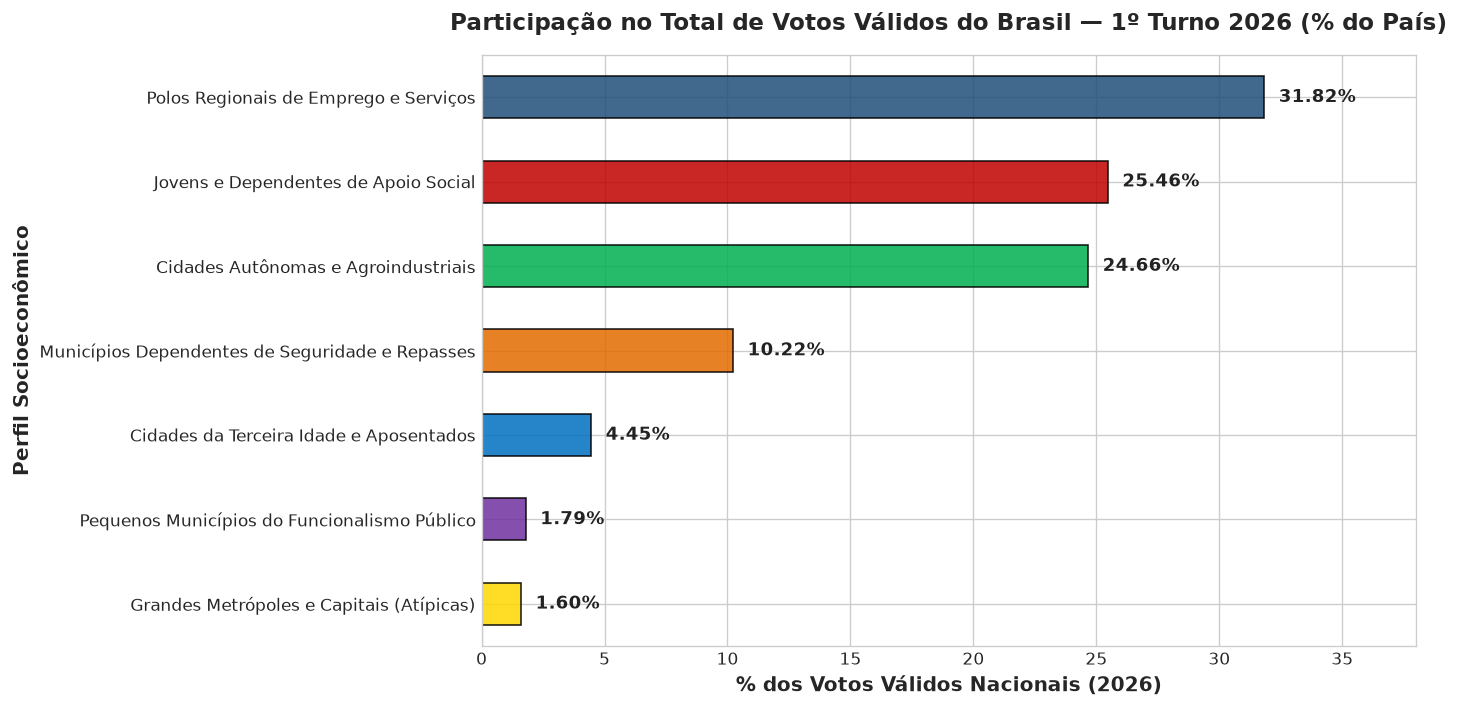

In [4]:
# Gráfico 1: Peso de Cada Perfil no Total de Votos Válidos do Brasil em 2026
plt.figure(figsize=(12, 6))

cores_perfis = ['#1F4E79', '#C00000', '#00B050', '#E26B00', '#0070C0', '#7030A0', '#FFD700']
ax1 = resumo_peso_26['pct_votos_validos_nacional_2026'].plot(kind='barh', color=cores_perfis, edgecolor='black', alpha=0.85)
plt.gca().invert_yaxis()
plt.title('Participação no Total de Votos Válidos do Brasil — 1º Turno 2026 (% do País)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('% dos Votos Válidos Nacionais (2026)', fontsize=12, fontweight='bold')
plt.ylabel('Perfil Socioeconômico', fontsize=12, fontweight='bold')

for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.2f}%", (p.get_width() + 0.6, p.get_y() + p.get_height() / 2.),
                 va='center', fontsize=11, fontweight='bold', color='#222222')
plt.xlim(0, 38)
plt.tight_layout()
plt.show()


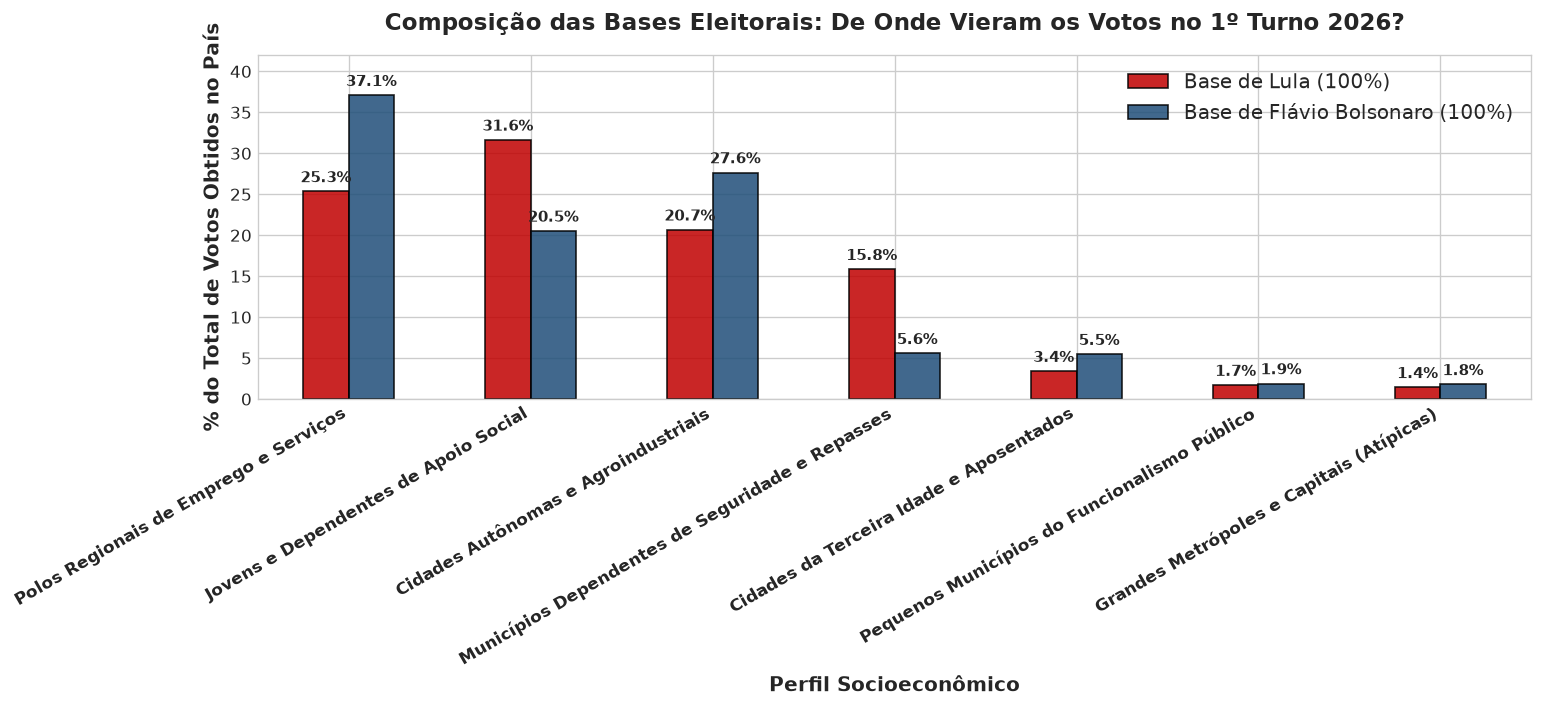

In [5]:
# Gráfico 2: De Onde Vieram os Votos de Lula e de Flávio Bolsonaro em 2026?
df_comp_26 = resumo_peso_26[['pct_do_total_lula_2026', 'pct_do_total_flavio_2026']].copy()
df_comp_26.columns = ['Base de Lula (100%)', 'Base de Flávio Bolsonaro (100%)']

ax2 = df_comp_26.plot(kind='bar', color=['#C00000', '#1F4E79'], edgecolor='black', alpha=0.85, figsize=(13, 6))
plt.title('Composição das Bases Eleitorais: De Onde Vieram os Votos no 1º Turno 2026?', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('% do Total de Votos Obtidos no País', fontsize=12, fontweight='bold')
plt.xlabel('Perfil Socioeconômico', fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=10, fontweight='bold')
plt.legend(fontsize=12)
plt.ylim(0, 42)

for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.7),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 🗳️ 3. Análise da Votação no 1º Turno de 2026 por Perfil de Cidade
Examinamos a média percentual de votos válidos obtida pelos candidatos presidenciais no **1º Turno de 2026** por perfil de município.


📋 VOTAÇÃO MÉDIA NO 1º TURNO DE 2026 POR PERFIL SOCIOECONÔMICO:


,Qtd_Cidades,Lula_2026_1T_pct,Flavio_2026_1T_pct,Caiado_2026_1T_pct,Zema_2026_1T_pct,Vantagem_Lula
perfil_analise,,,,,,
Municípios Dependentes de Seguridade e Repasses,766,71.19,24.66,0.88,0.05,46.53
Jovens e Dependentes de Apoio Social,1414,63.80,31.76,1.01,0.05,32.04
Pequenos Municípios do Funcionalismo Público,573,44.00,48.77,3.23,0.24,-4.77
Grandes Metrópoles e Capitais (Atípicas),5,38.65,54.02,1.72,0.15,-15.37
Cidades Autônomas e Agroindustriais,957,35.99,56.36,2.85,0.26,-20.37
Polos Regionais de Emprego e Serviços,1134,35.59,56.79,2.60,0.29,-21.20
Cidades da Terceira Idade e Aposentados,722,34.53,58.31,2.37,0.27,-23.78


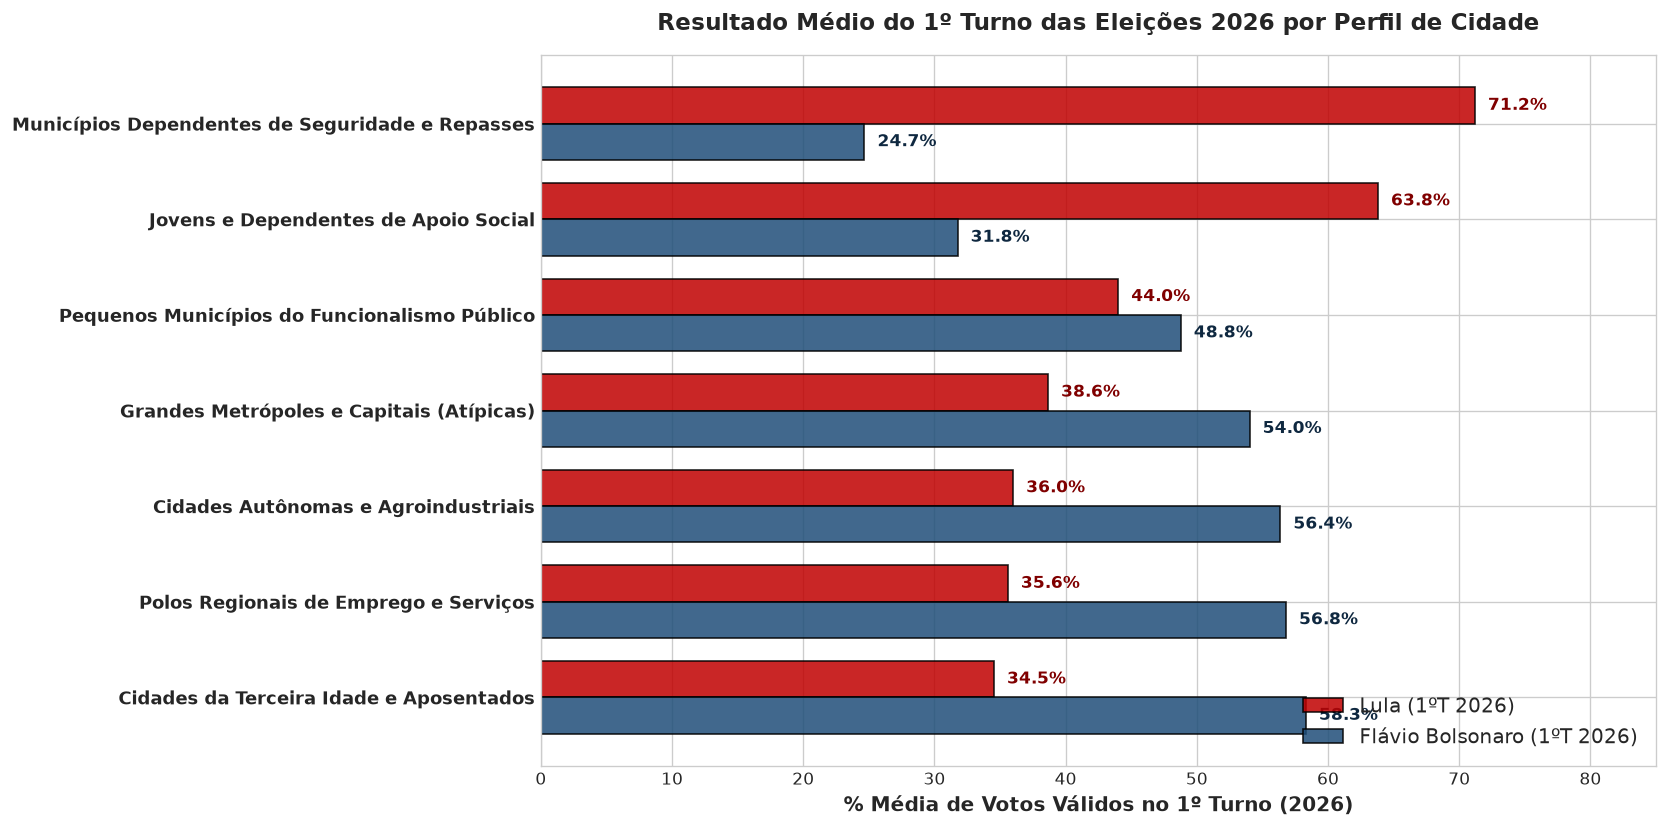

In [6]:
resumo_voto_26 = df_eleitoral.groupby('perfil_analise').agg({
    'cod_ibge7': 'count',
    'pct_lula_2026_1t': 'mean',
    'pct_flavio_2026_1t': 'mean',
    'pct_caiado_2026_1t': 'mean',
    'pct_zema_2026_1t': 'mean'
}).round(2)

resumo_voto_26.columns = ['Qtd_Cidades', 'Lula_2026_1T_pct', 'Flavio_2026_1T_pct', 'Caiado_2026_1T_pct', 'Zema_2026_1T_pct']
resumo_voto_26['Vantagem_Lula'] = (resumo_voto_26['Lula_2026_1T_pct'] - resumo_voto_26['Flavio_2026_1T_pct']).round(2)
resumo_voto_26 = resumo_voto_26.sort_values(by='Lula_2026_1T_pct', ascending=False)

print("📋 VOTAÇÃO MÉDIA NO 1º TURNO DE 2026 POR PERFIL SOCIOECONÔMICO:")
display(resumo_voto_26)

# Gráfico Comparativo: Votação 1º Turno 2026 (Lula x Flávio Bolsonaro)
fig, ax = plt.subplots(figsize=(14, 7))
y_pos = np.arange(len(resumo_voto_26))
bar_width = 0.38

rects1 = ax.barh(y_pos - bar_width/2, resumo_voto_26['Lula_2026_1T_pct'], bar_width, label='Lula (1ºT 2026)', color='#C00000', alpha=0.85, edgecolor='black')
rects2 = ax.barh(y_pos + bar_width/2, resumo_voto_26['Flavio_2026_1T_pct'], bar_width, label='Flávio Bolsonaro (1ºT 2026)', color='#1F4E79', alpha=0.85, edgecolor='black')

ax.set_yticks(y_pos)
ax.set_yticklabels(resumo_voto_26.index, fontsize=11, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('% Média de Votos Válidos no 1º Turno (2026)', fontsize=12, fontweight='bold')
ax.set_title('Resultado Médio do 1º Turno das Eleições 2026 por Perfil de Cidade', fontsize=14, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=12)

for p in rects1:
    ax.annotate(f"{p.get_width():.1f}%", (p.get_width() + 1, p.get_y() + p.get_height() / 2.), va='center', fontsize=10, fontweight='bold', color='#800000')
for p in rects2:
    ax.annotate(f"{p.get_width():.1f}%", (p.get_width() + 1, p.get_y() + p.get_height() / 2.), va='center', fontsize=10, fontweight='bold', color='#0F2840')

plt.xlim(0, 85)
plt.tight_layout()
plt.show()


## 📉 4. Trajetória Histórica da Abstenção (2010 a 2026 — 5 Eleições Presidenciais)
Acompanhamos a taxa de abstenção (% de eleitores aptos que deixaram de votar) ao longo de cinco eleições presidenciais consecutivas: **2010, 2014, 2018, 2022 e 2026**.


📋 HISTÓRICO DE ABSTENÇÃO (% DO ELEITORADO) DE 2010 A 2026:


,Abst_2010,Abst_2014,Abst_2018,Abst_2022,Abst_2026,Variacao_2010_2026
perfil_analise,,,,,,
Cidades Autônomas e Agroindustriais,21.1,21.7,22.3,20.9,21.8,0.7
Cidades da Terceira Idade e Aposentados,18.0,18.2,19.0,18.2,19.8,1.8
Grandes Metrópoles e Capitais (Atípicas),19.0,16.8,19.9,19.1,19.0,0.0
Jovens e Dependentes de Apoio Social,26.0,24.8,23.3,22.4,19.5,-6.5
Municípios Dependentes de Seguridade e Repasses,26.3,25.9,23.3,21.9,19.4,-6.9
Pequenos Municípios do Funcionalismo Público,23.4,24.3,25.6,22.5,22.9,-0.5
Polos Regionais de Emprego e Serviços,20.8,21.4,22.5,20.9,21.7,0.9


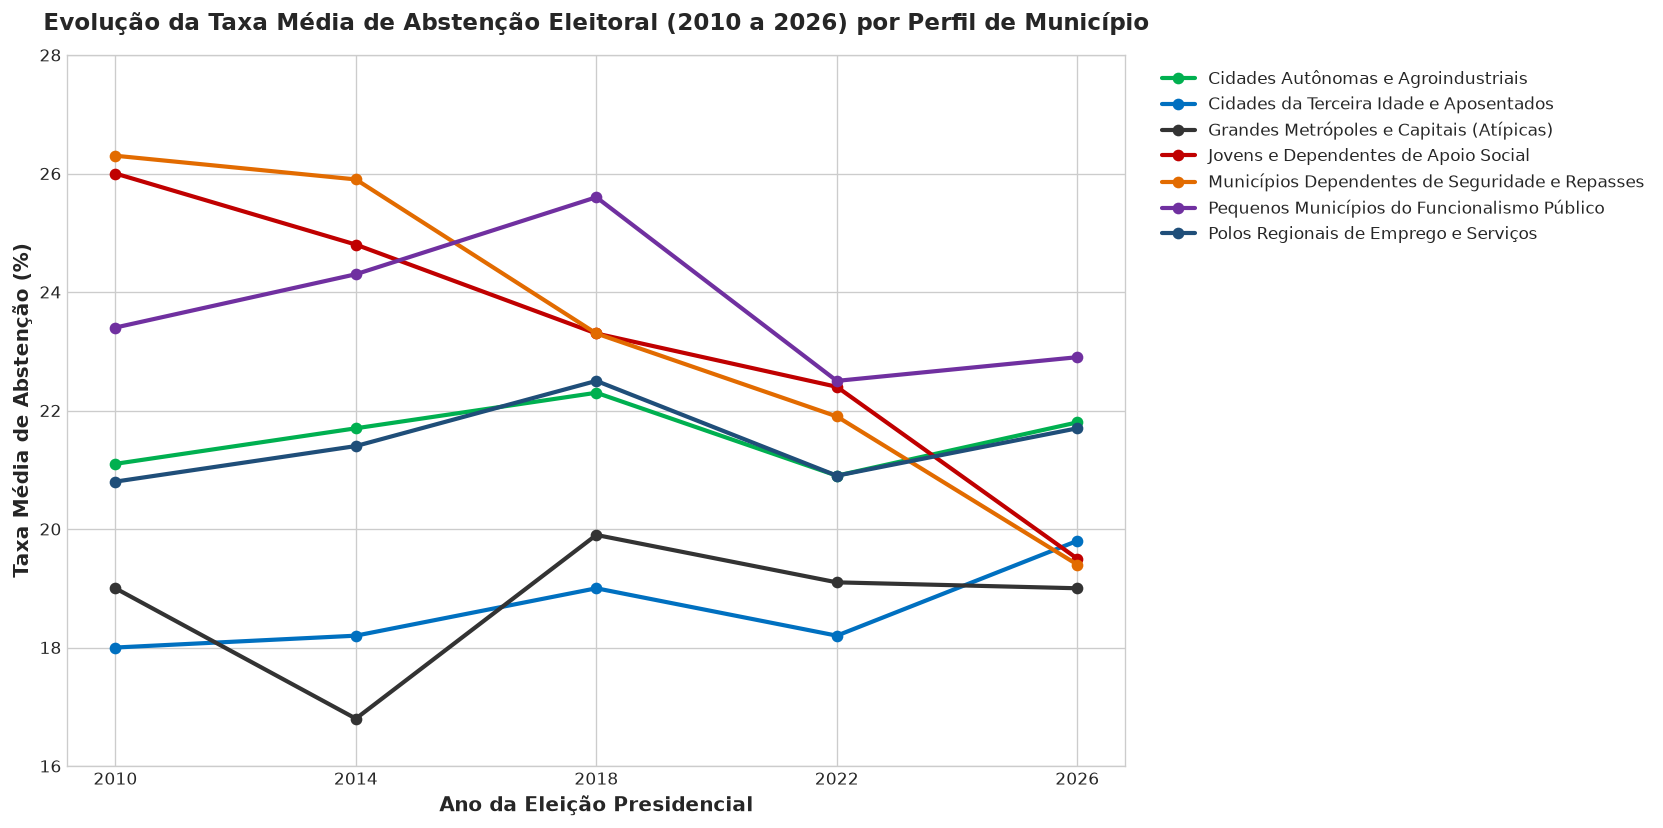

In [7]:
resumo_hist_abst = df_eleitoral.groupby('perfil_analise').agg({
    'taxa_abst_2010': 'mean',
    'taxa_abst_2014': 'mean',
    'taxa_abst_2018': 'mean',
    'taxa_abst_2022': 'mean',
    'taxa_abst_2026_1t': 'mean'
}).round(1)

resumo_hist_abst.columns = ['Abst_2010', 'Abst_2014', 'Abst_2018', 'Abst_2022', 'Abst_2026']
resumo_hist_abst['Variacao_2010_2026'] = (resumo_hist_abst['Abst_2026'] - resumo_hist_abst['Abst_2010']).round(1)

print("📋 HISTÓRICO DE ABSTENÇÃO (% DO ELEITORADO) DE 2010 A 2026:")
display(resumo_hist_abst)

# Gráfico de Linhas: Trajetória Histórica de 5 Eleições
plt.figure(figsize=(14, 7))
anos = [2010, 2014, 2018, 2022, 2026]
paleta = {
    'Jovens e Dependentes de Apoio Social': '#C00000',
    'Municípios Dependentes de Seguridade e Repasses': '#E26B00',
    'Pequenos Municípios do Funcionalismo Público': '#7030A0',
    'Polos Regionais de Emprego e Serviços': '#1F4E79',
    'Cidades Autônomas e Agroindustriais': '#00B050',
    'Cidades da Terceira Idade e Aposentados': '#0070C0',
    'Grandes Metrópoles e Capitais (Atípicas)': '#333333'
}

for perfil, row in resumo_hist_abst.iterrows():
    valores = [row['Abst_2010'], row['Abst_2014'], row['Abst_2018'], row['Abst_2022'], row['Abst_2026']]
    plt.plot(anos, valores, marker='o', lw=2.5, label=perfil, color=paleta.get(perfil, '#666666'))

plt.title('Evolução da Taxa Média de Abstenção Eleitoral (2010 a 2026) por Perfil de Município', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano da Eleição Presidencial', fontsize=12, fontweight='bold')
plt.ylabel('Taxa Média de Abstenção (%)', fontsize=12, fontweight='bold')
plt.xticks(anos)
plt.ylim(16, 28)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()


## 👥 5. Diagnóstico de Abstenção por Faixa Etária
Avaliamos a taxa de abstenção em cada estrato etário do eleitorado (Jovens 16-24, Adultos 25-59 e Idosos 60+).


📋 ABSTENÇÃO POR FAIXA ETÁRIA POR PERFIL SOCIOECONÔMICO:


,Abst_Jovem_16_24,Abst_Adulto_25_59,Abst_Idoso_60+
perfil_analise,,,
Cidades Autônomas e Agroindustriais,22.9,16.7,31.0
Cidades da Terceira Idade e Aposentados,19.2,13.9,27.3
Grandes Metrópoles e Capitais (Atípicas),18.7,15.4,31.5
Jovens e Dependentes de Apoio Social,24.1,18.6,34.0
Municípios Dependentes de Seguridade e Repasses,22.2,17.3,35.0
Pequenos Municípios do Funcionalismo Público,24.9,19.2,29.6
Polos Regionais de Emprego e Serviços,22.5,16.5,31.5


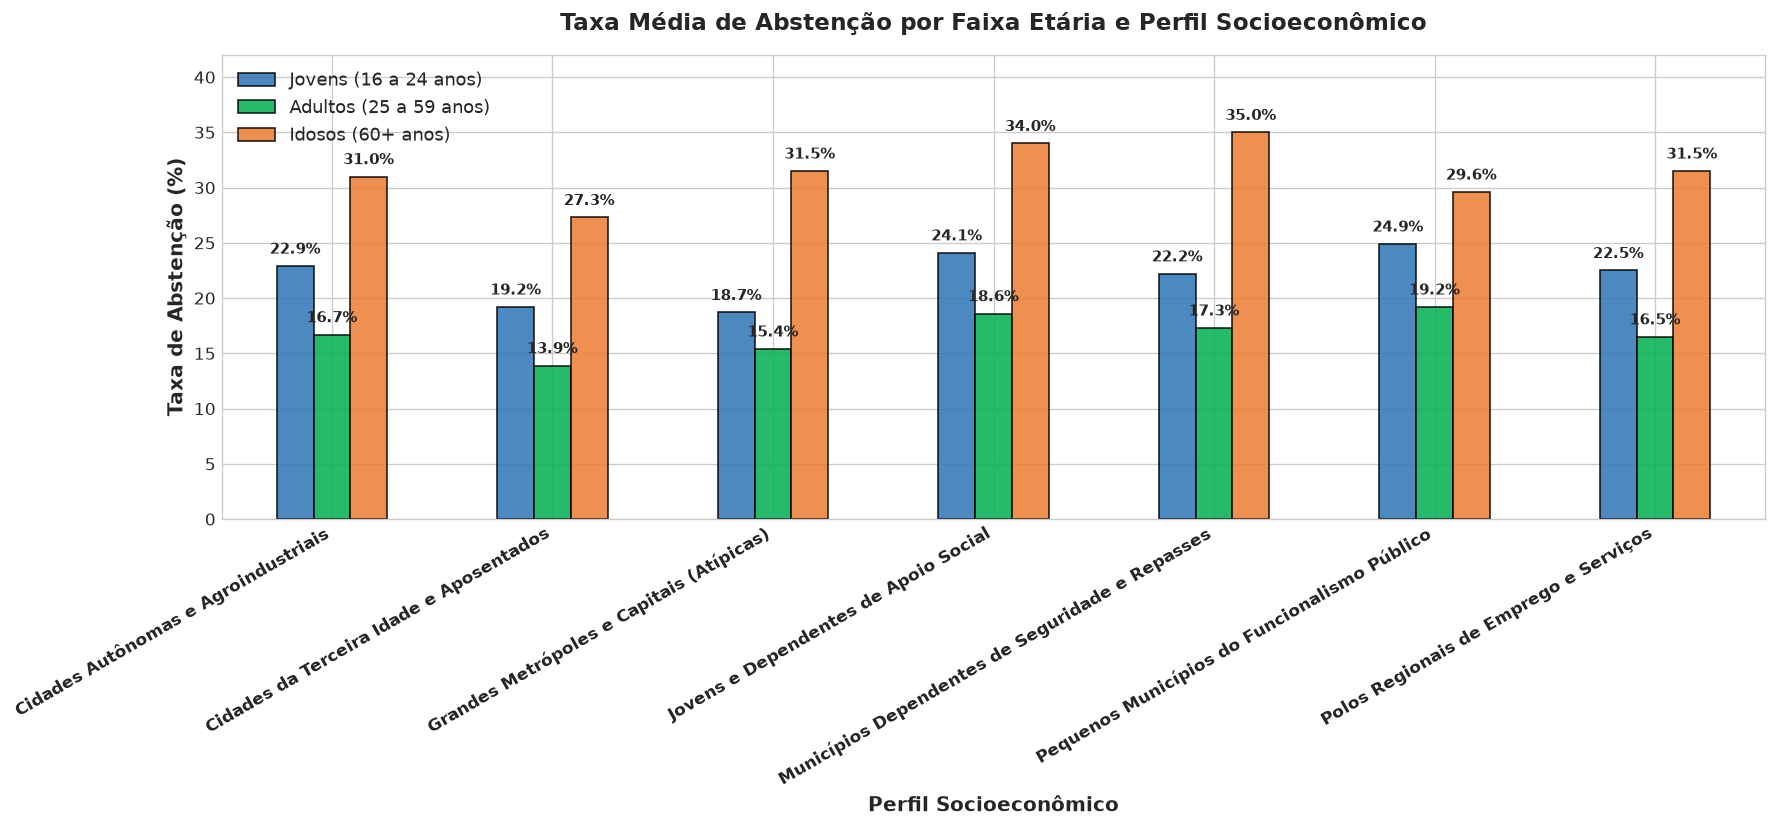

In [8]:
resumo_idade = df_eleitoral.groupby('perfil_analise').agg({
    'taxa_abstencao_jovem_16_24_pct': 'mean',
    'taxa_abstencao_adulto_25_59_pct': 'mean',
    'taxa_abstencao_idoso_60_mais_pct': 'mean'
}).round(1)

resumo_idade.columns = ['Abst_Jovem_16_24', 'Abst_Adulto_25_59', 'Abst_Idoso_60+']
print("📋 ABSTENÇÃO POR FAIXA ETÁRIA POR PERFIL SOCIOECONÔMICO:")
display(resumo_idade)

# Gráfico de barras agrupadas: Faixa Etária por Perfil
ax = resumo_idade[['Abst_Jovem_16_24', 'Abst_Adulto_25_59', 'Abst_Idoso_60+']].plot(
    kind='bar', figsize=(15, 7), color=['#2E75B6', '#00B050', '#ED7D31'], edgecolor='black', alpha=0.85
)
plt.title('Taxa Média de Abstenção por Faixa Etária e Perfil Socioeconômico', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Perfil Socioeconômico', fontsize=12, fontweight='bold')
plt.ylabel('Taxa de Abstenção (%)', fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=10, fontweight='bold')
plt.legend(['Jovens (16 a 24 anos)', 'Adultos (25 a 59 anos)', 'Idosos (60+ anos)'], fontsize=11)
plt.ylim(0, 42)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.8),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 🗺️ 6. Mapa Geográfico do Brasil com as Cidades Pintadas por Perfil
Plotamos os **5.571 municípios brasileiros** georreferenciados sobre a malha territorial oficial das 27 Unidades da Federação do IBGE.


/tmp/ipykernel_26570/1683912148.py:56: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_26570/1683912148.py:57: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.savefig('dados_prioridades/mapa_brasil_perfis_municipios.png', dpi=300, bbox_inches='tight')


/home/hianara/trad_x_municipio/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


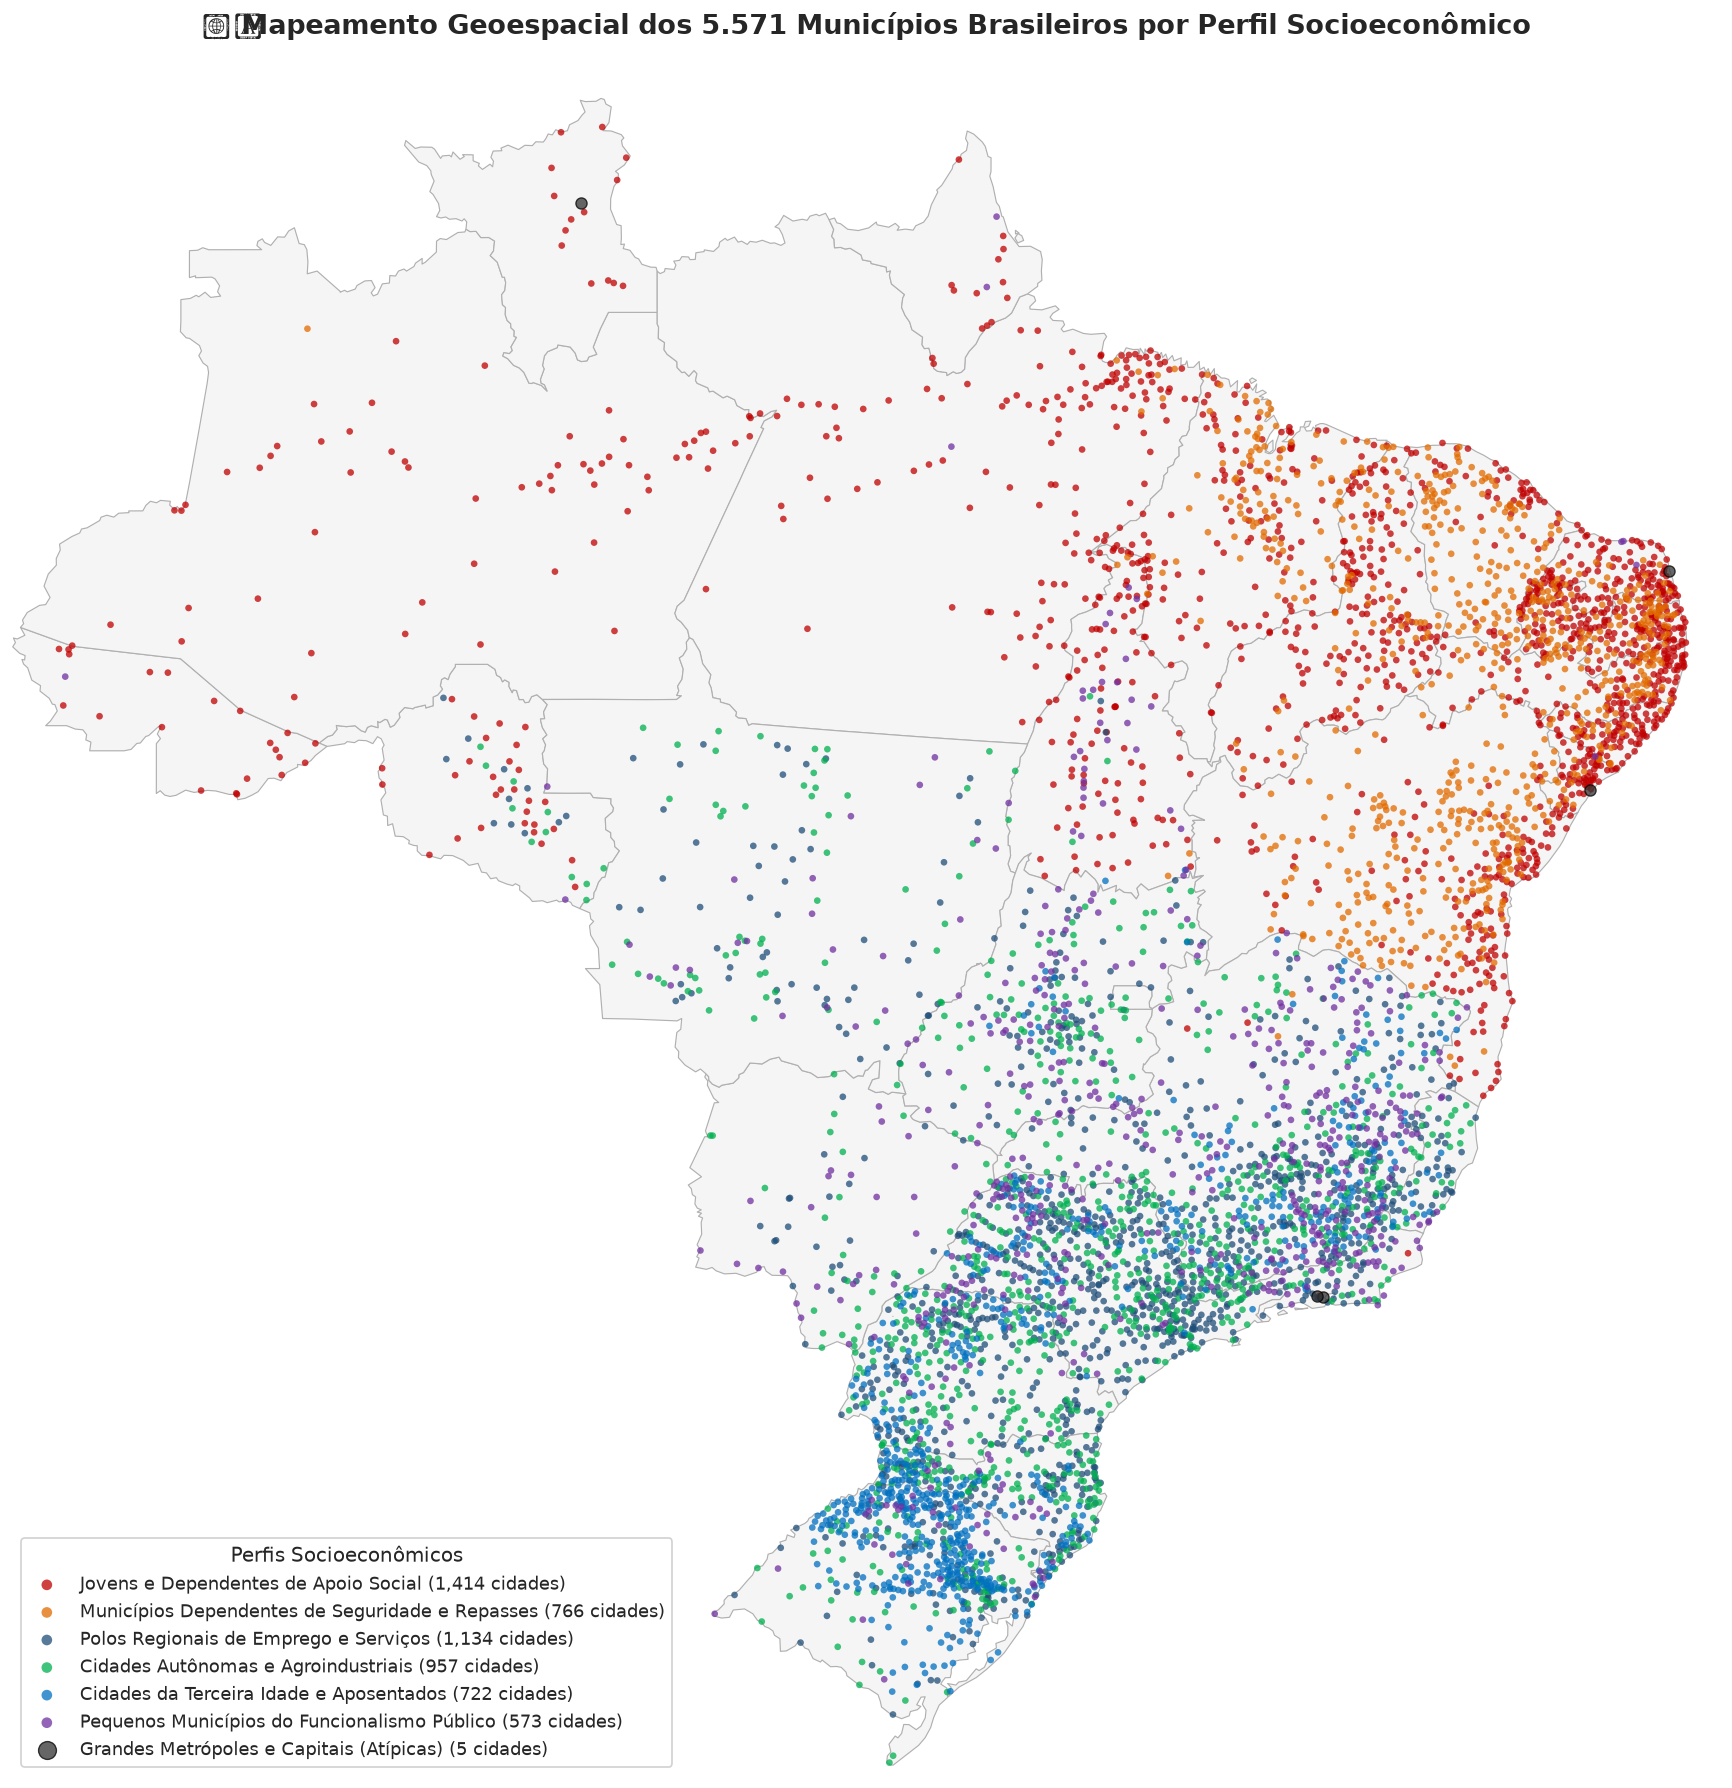

✅ Mapa salvo em alta resolução em 'dados_prioridades/mapa_brasil_perfis_municipios.png'!


In [9]:
# Carregamento da Malha Territorial das UFs (IBGE)
with open('dados_prioridades/brasil_estados.json', 'r', encoding='utf-8') as f:
    geojson_br = json.load(f)

cores_mapa = {
    'Jovens e Dependentes de Apoio Social': '#C00000',
    'Municípios Dependentes de Seguridade e Repasses': '#E26B00',
    'Polos Regionais de Emprego e Serviços': '#1F4E79',
    'Cidades Autônomas e Agroindustriais': '#00B050',
    'Cidades da Terceira Idade e Aposentados': '#0070C0',
    'Pequenos Municípios do Funcionalismo Público': '#7030A0',
    'Grandes Metrópoles e Capitais (Atípicas)': '#333333'
}

fig, ax = plt.subplots(figsize=(15, 15))

# 1. Desenhar os polígonos dos 27 Estados
patches_uf = []
for feat in geojson_br['features']:
    geom = feat['geometry']
    coords = geom['coordinates']
    if geom['type'] == 'Polygon':
        for poly in coords:
            patches_uf.append(Polygon(poly, closed=True))
    elif geom['type'] == 'MultiPolygon':
        for multi in coords:
            for poly in multi:
                patches_uf.append(Polygon(poly, closed=True))

p_col = PatchCollection(patches_uf, facecolor='#F5F5F5', edgecolor='#B0B0B0', linewidth=0.7, zorder=1)
ax.add_collection(p_col)

# 2. Plotar os municípios por perfil
df_plot = df_eleitoral[df_eleitoral['latitude'].notna() & df_eleitoral['longitude'].notna()].copy()

for perfil, cor in cores_mapa.items():
    sub = df_plot[df_plot['perfil_analise'] == perfil]
    tam = 16 if 'Atípicas' not in perfil else 45
    borda = 'none' if 'Atípicas' not in perfil else 'black'
    z = 2 if 'Atípicas' not in perfil else 5
    
    ax.scatter(
        sub['longitude'], sub['latitude'],
        c=cor, label=f"{perfil} ({len(sub):,} cidades)",
        s=tam, alpha=0.75, edgecolors=borda, linewidth=0.8, zorder=z
    )

ax.set_xlim(-74, -34)
ax.set_ylim(-34, 6)
ax.set_aspect('equal')
ax.axis('off')

plt.title('🗺️ Mapeamento Geoespacial dos 5.571 Municípios Brasileiros por Perfil Socioeconômico', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=11, markerscale=1.6, title='Perfis Socioeconômicos', title_fontsize=12)

plt.tight_layout()
plt.savefig('dados_prioridades/mapa_brasil_perfis_municipios.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Mapa salvo em alta resolução em 'dados_prioridades/mapa_brasil_perfis_municipios.png'!")


## 💾 7. Exportação da Base Completa Integrada (Socioeconômica + Eleitoral 2026)
Exportamos a base unificada com todas as 5.571 cidades, seus perfis socioeconômicos reclassificados e todas as variáveis de votação de 2026 e séries temporais.


In [10]:
out_xlsx_integrado = 'dados_prioridades/cruzamento_perfil_x_eleicao_completo.xlsx'
out_csv_integrado = 'dados_prioridades/cruzamento_perfil_x_eleicao_completo.csv'

with pd.ExcelWriter(out_xlsx_integrado, engine='openpyxl') as writer:
    df_eleitoral.to_excel(writer, sheet_name='Base_Consolidada_5571', index=False)
    resumo_peso_26.to_excel(writer, sheet_name='Peso_Eleitoral_2026')
    resumo_voto_26.to_excel(writer, sheet_name='Votacao_1T_2026')
    resumo_hist_abst.to_excel(writer, sheet_name='Historico_Abstencao_2010_2026')
    resumo_idade.to_excel(writer, sheet_name='Abstencao_Idade')

df_eleitoral.to_csv(out_csv_integrado, sep=';', index=False, encoding='utf-8')
print(f"🎉 Base completa com Eleições 2026 exportada com sucesso:")
print(f" - {out_xlsx_integrado}")
print(f" - {out_csv_integrado}")
print("Amostra das primeiras 5 cidades com dados de 2026:")
display(df_eleitoral[['cod_ibge7', 'municipio', 'uf', 'perfil_analise', 'pct_lula_2026_1t', 'pct_flavio_2026_1t', 'taxa_abst_2026_1t']].head(5))


🎉 Base completa com Eleições 2026 exportada com sucesso:
 - dados_prioridades/cruzamento_perfil_x_eleicao_completo.xlsx
 - dados_prioridades/cruzamento_perfil_x_eleicao_completo.csv
Amostra das primeiras 5 cidades com dados de 2026:


,cod_ibge7,municipio,uf,perfil_analise,pct_lula_2026_1t,pct_flavio_2026_1t,taxa_abst_2026_1t
0,1100015,Alta Floresta D'Oeste,RO,Polos Regionais de Emprego e Serviços,25.22,70.06,21.09
1,1100023,Ariquemes,RO,Cidades Autônomas e Agroindustriais,18.21,76.30,23.24
2,1100031,Cabixi,RO,Cidades Autônomas e Agroindustriais,27.03,68.37,20.16
3,1100049,Cacoal,RO,Cidades Autônomas e Agroindustriais,22.48,70.15,21.35
4,1100056,Cerejeiras,RO,Jovens e Dependentes de Apoio Social,17.64,77.63,21.59
